In [1]:
from collections import Counter
import pandas as pd
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage3\397×87.xlsx")
X = data.iloc[:, 3:]
print(X)
feature_names = X.columns
X = StandardScaler().fit_transform(X)

min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)
X.shape

     band_gap     vbm    efermi   density  MagpieData mean MendeleevNumber  \
0      3.9641  1.5315  1.620862  3.963466                        62.944444   
1      5.0780  1.5258  1.570907  3.970678                        67.952381   
2      5.2118  1.2042  1.237303  3.985401                        67.904762   
3      4.0463  1.2514  5.297637  3.445198                        68.166667   
4      4.8124  1.1115  1.119990  3.694735                        71.093750   
..        ...     ...       ...       ...                              ...   
392    3.5439  2.3774  2.403277  4.073992                        67.170732   
393    4.2023  2.0134  2.000341  3.669853                        70.750000   
394    5.3364  0.6408  0.653819  3.127676                        73.705882   
395    4.4992  4.1609  4.313224  3.797135                        73.913043   
396    4.6260  1.6168  1.740793  4.115359                        64.625000   

     MagpieData minimum AtomicWeight  MagpieData range MeltingT

(397, 87)

Computing t-SNE embedding...
t-SNE embedding completed in 1.89s
Visualization saved as 'tsne_visualization.png'


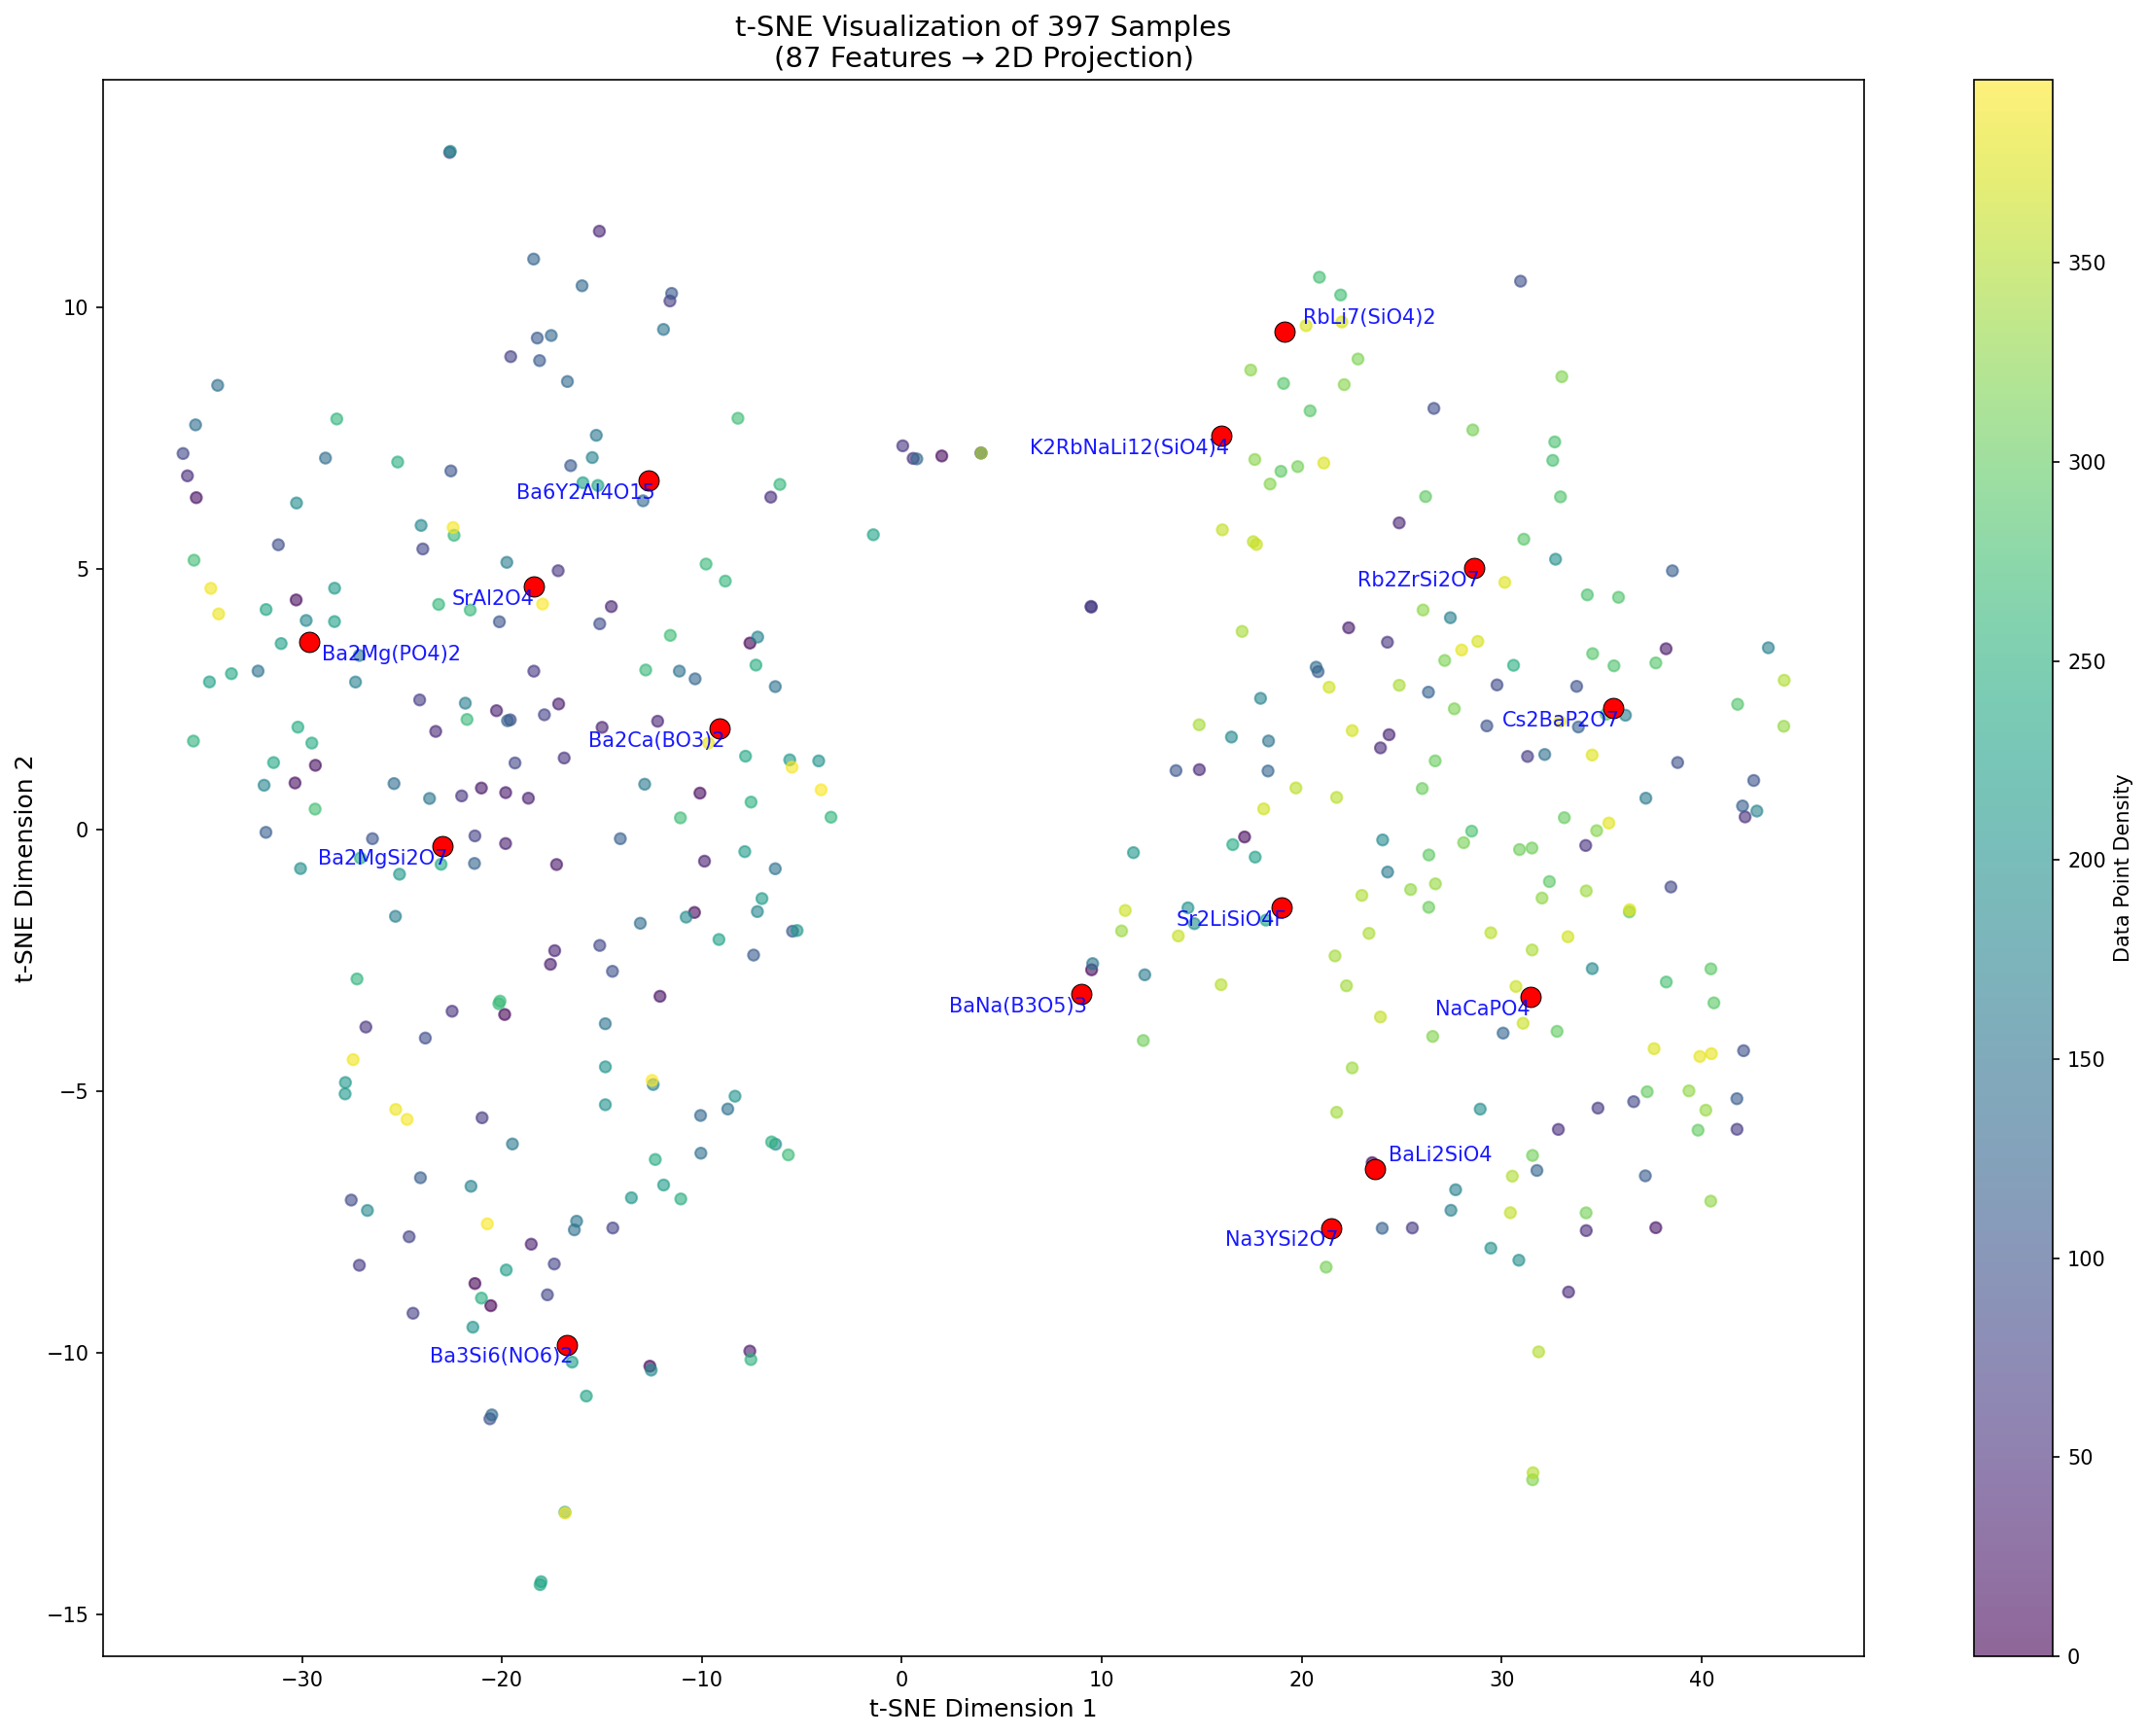

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from time import time
from adjustText import adjust_text


label_col = data.iloc[:, 2]


n_samples = X.shape[0]
n_features = X.shape[1]


print("Computing t-SNE embedding...")
tsne = TSNE(n_components=2,
            perplexity=30,
            random_state=42)


t0 = time()
X_tsne = tsne.fit_transform(X)
print(f"t-SNE embedding completed in {time()-t0:.2f}s")


plt.figure(figsize=(16, 12), dpi=150)


scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
                     c=np.arange(n_samples),
                     cmap='viridis',
                     alpha=0.6,
                     s=30)


cbar = plt.colorbar(scatter)
cbar.set_label('Data Point Density')


def extract_numbers(file_path):
    df = pd.read_excel(file_path)
    valid_numbers = []
    for index, value in df['composition'].items():
        if not pd.isna(value):
            valid_numbers.append(df.at[index, 'number'])
    return valid_numbers

file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage3\benchmark3.xlsx"
highlight_indices = extract_numbers(file_path)


texts = []


for idx in highlight_indices:
    idx = idx - 1
    if idx < len(X_tsne):

        plt.scatter(X_tsne[idx, 0], X_tsne[idx, 1],
                   c='red', s=100, edgecolors='black', linewidths=0.5,
                   zorder=3)


        text = plt.text(X_tsne[idx, 0], X_tsne[idx, 1],
                       str(label_col.iloc[idx]),
                       fontsize=10,
                       color='blue',
                       alpha=0.9,
                       ha='center', va='center',
                       zorder=4)
        texts.append(text)


if 'adjust_text' in globals() and callable(adjust_text):
    adjust_text(texts,
                only_move={'points':'y', 'texts':'xy'},
                # arrowprops=dict(arrowstyle='->', color='gray', lw=0.5),
                expand_points=(1.2, 1.5),
                expand_text=(1.2, 1.5),
                force_text=(0.2, 0.5),
                force_points=(0.2, 0.5))
else:
    print("Warning: adjust_text function not available, using manual adjustment")

    for i, text in enumerate(texts):
        if i % 3 == 0:
            text.set_position((text.get_position()[0], text.get_position()[1]+0.5))
        elif i % 3 == 1:
            text.set_position((text.get_position()[0]+0.3, text.get_position()[1]-0.3))


plt.title(f't-SNE Visualization of {n_samples} Samples\n'
          f'({n_features} Features → 2D Projection)', fontsize=14)
plt.xlabel('t-SNE Dimension 1', fontsize=12)
plt.ylabel('t-SNE Dimension 2', fontsize=12)


plt.tight_layout()


plt.savefig('tsne_visualization.png', dpi=300, bbox_inches='tight')
print("Visualization saved as 'tsne_visualization.png'")

plt.show()

In [3]:
from collections import Counter
import pandas as pd
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage3\397×87.xlsx")
X = data.iloc[:, 3:]
X
feature_names = X.columns
X = StandardScaler().fit_transform(X)

min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)
X.shape

(397, 87)

In [4]:

def extract_numbers(file_path):
    df = pd.read_excel(file_path)
    valid_numbers = []
    for index, value in df['composition'].items():
        if not pd.isna(value):
            valid_numbers.append(int(df.at[index, 'number']))
    return valid_numbers

file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage3\benchmark3.xlsx"
reported_structures = extract_numbers(file_path)
# print(reported_structures)

for j in range(10, 100, 5):
    j = j/100

    pca = PCA(n_components= j)
    pca_data = pca.fit_transform(X)
    num_pca = pca_data.shape[1]

    for i in range(3, 7):
        kmeans_plus = KMeans(n_clusters=i, init='k-means++', n_init= 'auto', tol=1e-5, algorithm="elkan", max_iter = 1000, random_state=42)
        kmeans_plus.fit(pca_data)
        labels = kmeans_plus.labels_

        data[f'cluster_{i}'] = labels
        print(f"\nNumber of clusters k={i}:", f"\nPCA retained variance={j}:", f"\nSilhouette score: {silhouette_score(pca_data, labels):.2f}", f"\nCalinski-Harabasz score: {calinski_harabasz_score(pca_data, labels):.2f}")
        dict = {}

        label_1 = []
        for num  in  reported_structures:
            label = labels[num-1]
            label_1.append(int(label))
        print(label_1)

        for cluster in range(i):

            cluster_samples = data[data[f'cluster_{i}'] == cluster]
                # print(cluster_samples)

            total_in_cluster = len(cluster_samples)


            reported_in_cluster = len([num for num in cluster_samples['number'] if num in reported_structures])
            dict[cluster] = (reported_in_cluster, total_in_cluster)
        for value in dict.values():
            if value[0] == 0:
                for key, value in dict.items():

                    formatted_value = f"{value[0]}/{value[1]}"

                    print(f"Cluster {key}: {formatted_value}")
                    #print(f"Cluster {cluster}: {reported_in_cluster}/{total_in_cluster} "
                    #    f"(Reported ratio: {reported_in_cluster/total_in_cluster:.2%})")


Number of clusters k=3: 
PCA retained variance=0.1: 
Silhouette score: 0.71 
Calinski-Harabasz score: 2777.19
[1, 2, 2, 0, 2, 0, 0, 0, 0, 0, 2, 0, 2, 2, 1]

Number of clusters k=4: 
PCA retained variance=0.1: 
Silhouette score: 0.57 
Calinski-Harabasz score: 3112.62
[1, 2, 2, 0, 2, 0, 0, 0, 3, 0, 2, 0, 2, 2, 1]

Number of clusters k=5: 
PCA retained variance=0.1: 
Silhouette score: 0.55 
Calinski-Harabasz score: 3344.87
[1, 4, 2, 0, 4, 0, 0, 0, 3, 0, 2, 0, 2, 2, 1]

Number of clusters k=6: 
PCA retained variance=0.1: 
Silhouette score: 0.58 
Calinski-Harabasz score: 3461.59
[1, 2, 2, 0, 2, 0, 0, 0, 0, 4, 5, 0, 5, 2, 1]
Cluster 0: 6/145
Cluster 1: 2/41
Cluster 2: 4/64
Cluster 3: 0/63
Cluster 4: 1/19
Cluster 5: 2/65

Number of clusters k=3: 
PCA retained variance=0.15: 
Silhouette score: 0.71 
Calinski-Harabasz score: 2777.19
[1, 2, 2, 0, 2, 0, 0, 0, 0, 0, 2, 0, 2, 2, 1]

Number of clusters k=4: 
PCA retained variance=0.15: 
Silhouette score: 0.57 
Calinski-Harabasz score: 3112.62
[1, 2

In [5]:
pca = PCA(n_components= 0.2, random_state=42)
new_data = pca.fit_transform(X)
print(new_data.shape)
ratios = pca.explained_variance_ratio_
components = pca.components_
X = pd.DataFrame(X)

components_df = pd.DataFrame(
    components,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(components.shape[0])]
)

output_file = "pca_components.xlsx"
components_df.to_excel(output_file, index=True)


i = 6
kmeans_plus = KMeans(n_clusters=i, init='k-means++', n_init= 'auto', tol=1e-5, algorithm="elkan", max_iter = 1000, random_state=42)
kmeans_plus.fit(new_data)
labels = kmeans_plus.labels_
print(f"Silhouette score: {silhouette_score(new_data, labels):.2f}")
print(f"Calinski-Harabasz score: {calinski_harabasz_score(new_data, labels):.2f}")
df = pd.DataFrame(labels)
df.to_excel("kmeans_result.xlsx")

data[f'cluster_{i}'] = labels

print(f"\nNumber of clusters k={i}:")


for cluster in range(i):

    cluster_samples = data[data[f'cluster_{i}'] == cluster]
            # print(cluster_samples)

    total_in_cluster = len(cluster_samples)
    print(total_in_cluster)

    reported_in_cluster = len([num for num in cluster_samples['number'] if num in reported_structures])

    print(f"Cluster {cluster}: {reported_in_cluster}/{total_in_cluster} "
                f"(Reported ratio: {reported_in_cluster/total_in_cluster:.2%})")

(397, 1)
Silhouette score: 0.58
Calinski-Harabasz score: 3461.59

Number of clusters k=6:
145
Cluster 0: 6/145 (Reported ratio: 4.14%)
41
Cluster 1: 2/41 (Reported ratio: 4.88%)
64
Cluster 2: 4/64 (Reported ratio: 6.25%)
63
Cluster 3: 0/63 (Reported ratio: 0.00%)
19
Cluster 4: 1/19 (Reported ratio: 5.26%)
65
Cluster 5: 2/65 (Reported ratio: 3.08%)


In [6]:
import pandas as pd
from sklearn.decomposition import PCA
from openpyxl.styles import Font
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl import Workbook


wb = Workbook()
ws = wb.active


for r in dataframe_to_rows(components_df, index=True, header=True):
    ws.append(r)


red_bold_font = Font(color="FF0000", bold=True)


for row in range(2, ws.max_row + 1):

    values = [ws.cell(row=row, column=col).value for col in range(2, ws.max_column + 1)]


    values = [0 if v is None else v for v in values]


    abs_values = [abs(v) for v in values]
    top_10_indices = sorted(range(len(abs_values)), key=lambda i: abs_values[i], reverse=True)[:10]


    for idx in top_10_indices:
        ws.cell(row=row, column=idx + 2).font = red_bold_font


output_file = "pca_components_highlighted.xlsx"
wb.save(output_file)

print(f"The component-loading matrix has been saved to {output_file}, with the 10 largest absolute values highlighted.")

The component-loading matrix has been saved to pca_components_highlighted.xlsx, with the 10 largest absolute values highlighted.
